# Wetland Mapping with TropWet: Change Between Dates and Accuracy

*Section 13 — Case study: wetland mapping (TropWet), notebook 3 of 6.* Previous: `02_unmixing_and_classification`. Next: `04_finding_endmembers`.

A median composite shows one state of a wetland, and the composite of notebooks 01 and 02 mixes two dates 21 years apart. Because TropWet needs no training data, the same endmembers and rules can instead be applied to **each date on its own**, which makes it a natural tool for monitoring: the guide uses this for its water frequency map (Step 8). This notebook goes further:

- it classifies the 1997 (Landsat 5 TM) and 2018 (Landsat 8 OLI) images separately, with the endmember sets of notebook 01 and the per-pixel model choice (MESMA) of notebook 02;
- it maps the change in the wetland classes between the two dates, as a from–to table and a gain / loss map;
- it checks the classes against the reference polygons of the change detection notebooks (section 6), and calculates the accuracy of the open water class with `calc_acc_stats_ptonly`.

**You will learn:**
- how to apply one set of endmembers and class rules to several dates;
- how to summarise the change between two thematic maps with a from–to (transition) table and a gain / loss map;
- how to rasterise reference polygons with `rasterise_vec_lyr` and cross-tabulate them against a classification;
- how to sample reference points and calculate accuracy statistics with `calc_acc_stats_ptonly`;
- what an unsupervised, rule-based method like TropWet can and cannot tell you.

**Before you start:** run `01_composite_and_endmembers` (this notebook reads its per-date images and endmembers); notebook `02_unmixing_and_classification` explains the unmixing, MESMA and class rules used here.

**Data:** `outputs/inputs/sref_1997.tif`, `outputs/inputs/sref_2018.tif` and `outputs/endmembers/*.csv` (from notebook 01), and the reference polygons `../data/chg_data/training/*.geojson` (1997) and `../data/chg_data/training/2018/*.geojson` (2018). Outputs are written to `outputs/change/`.

**Run time:** < 1 minute.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

## 1. Import Modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import geopandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import rsgispy
import rsgispy.classification.classaccuracymetrics as acc_metrics
import rsgispy.imagespectral.unmixing as unmix
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imagecalc.stats import count_pxls_of_val
import rsgispy.imagespectral.mesma as mesma
from rsgispy.imagespectral.endmembers import make_spectral_library, read_endmembers_df
from rsgispy.imageutils.bands import select_img_bands
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.rasterise import rasterise_vec_lyr
from rsgispy.mapping.layout import MapPanel, create_map_panels

## 2. Define Input Data and Directories

In [2]:
in_dir = os.path.join("outputs", "inputs")
em_dir = os.path.join("outputs", "endmembers")
chg_dir = os.path.join("outputs", "change")
os.makedirs(chg_dir, exist_ok=True)

years = ["1997", "2018"]
sref_imgs = {year: os.path.join(in_dir, f"sref_{year}.tif") for year in years}

em_files = {
    "tropwet": os.path.join(em_dir, "endmembers_tropwet.csv"),
    "bright": os.path.join(em_dir, "endmembers_bright_sand.csv"),
}
em_dfs = {name: read_endmembers_df(em_file) for name, em_file in em_files.items()}

# Reference polygons (from the change detection notebooks, section 6).
ref_dirs = {"1997": "../data/chg_data/training", "2018": "../data/chg_data/training/2018"}
ref_classes = {1: "water", 2: "mangroves", 3: "other_terrestrial"}

## 3. Classify Each Date

### 3.1 The TropWet classes and helper functions

These are the functions of notebook 02: `fracs_to_pct` converts FCLS fractions to percentages and `classify_tropwet` applies the TropWet class rules.

In [3]:
TROPWET_CLASSES = {
    1: ("Open Water (OW)", "#08519C"),
    2: ("Emergent Flooded Vegetation (EFV)", "#3FB8AF"),
    3: ("Wet Bare Sand (WBS)", "#B39C4D"),
    4: ("Dense Vegetation (GV)", "#1B7837"),
    5: ("Dry Sparse Vegetation (DSV)", "#A6D96A"),
    6: ("Dry Bare Sand (DBS)", "#F4E2B8"),
    7: ("Mixed / Other", "#BDBDBD"),
}
cls_names = {val: name for val, (name, _) in TROPWET_CLASSES.items()}
cls_abbrv = {val: name.split("(")[-1].rstrip(")") if "(" in name else "Other"
             for val, name in cls_names.items()}


def fracs_to_pct(frac_img, pct_img):
    """FCLS fractions (no data -9999) to percentages (no data -999)."""
    band_maths(
        pct_img,
        ", ".join(f"{name} == -9999 ? -999 : 100 * {name}" for name in "WVS"),
        [BandDefn(name, frac_img, idx) for idx, name in enumerate("WVS", start=1)],
        band_names=["Water", "Vegetation", "Sand"],
        no_data_val=-999,
        use_pbar=False,
    )
    return pct_img


def classify_tropwet(pct_img, cls_img, hi=75, lo=25):
    """TropWet class rules (Hardy et al., 2020, Table 3) on W, V, S in %."""
    rules = [
        (1, f"W >= {hi}"),
        (2, f"W + V >= {hi} && V >= {lo} && V < {hi} && W >= {lo} && W < {hi}"),
        (3, f"W + S >= {hi} && W >= {lo} && W < {hi} && S >= {lo} && S < {hi}"),
        (4, f"V >= {hi}"),
        (5, f"V + S >= {hi} && V >= {lo} && V < {hi} && S >= {lo} && S < {hi}"),
        (6, f"S >= {hi}"),
    ]
    exp = "W < 0 ? 0 : "  # no data
    for code, rule in rules:
        exp += f"(({rule}) ? {code} : "
    exp += "7" + ")" * len(rules)  # anything else: Mixed / Other
    band_maths(
        cls_img,
        exp,
        [BandDefn(name, pct_img, idx) for idx, name in enumerate("WVS", start=1)],
        datatype=rsgispy.TYPE_8UINT,
        band_names=["tropwet_class"],
        no_data_val=0,
        use_pbar=False,
    )
    set_thematic_classes(cls_img, TROPWET_CLASSES)
    return cls_img

### 3.2 Unmix and classify

For each date, the image is unmixed with both endmember sets, the set with the lowest RMSE is kept per pixel (`mesma`, with the two-sand-spectra library of notebook 02), and the fractions are classified. Every date uses the **same endmembers**, derived from the composite, so a change in the fractions is a change on the ground (or in the conditions of the image), not a change of endmember.

The burn correction is not applied per date: as notebook 02 showed, it flags only a few pixels of turbid water in this area. With your own data, apply it to each date (with each date's own BAI threshold) if burned areas are common.

In [4]:
# The library of notebook 02: water, vegetation and the two sand spectra.
library = make_spectral_library(
    pd.DataFrame(
        {
            "water": em_dfs["tropwet"]["Water"],
            "vegetation": em_dfs["tropwet"]["Vegetation"],
            "wet_mud": em_dfs["tropwet"]["Sand"],
            "bright_sand": em_dfs["bright"]["Sand"],
        }
    ),
    ["Water", "Vegetation", "Sand", "Sand"],
)


def unmix_and_classify(refl_img, out_base):
    """MESMA with the two sand spectra (FCLS), % and TropWet classes."""
    mesma_out = f"{out_base}_mesma.tif"
    mesma.mesma(
        refl_img, mesma_out, library, levels=(3,), gain=1000.0,
        min_frac=None, max_frac=None, max_rmse=None, max_resid=None, use_pbar=False,
    )
    mesma_img = f"{out_base}_mesma_fcls.tif"
    select_img_bands(mesma_out, mesma_img, [1, 2, 3], calc_stats=False, use_pbar=False)
    pct_img = fracs_to_pct(mesma_img, f"{out_base}_mesma_pct.tif")
    return pct_img, classify_tropwet(pct_img, f"{out_base}_classes.tif")


pct_imgs, cls_imgs = {}, {}
for year in years:
    pct_imgs[year], cls_imgs[year] = unmix_and_classify(
        sref_imgs[year], os.path.join(chg_dir, f"tropwet_{year}")
    )
cls_imgs

{'1997': 'outputs/change/tropwet_1997_classes.tif',
 '2018': 'outputs/change/tropwet_2018_classes.tif'}

### 3.3 The two classifications

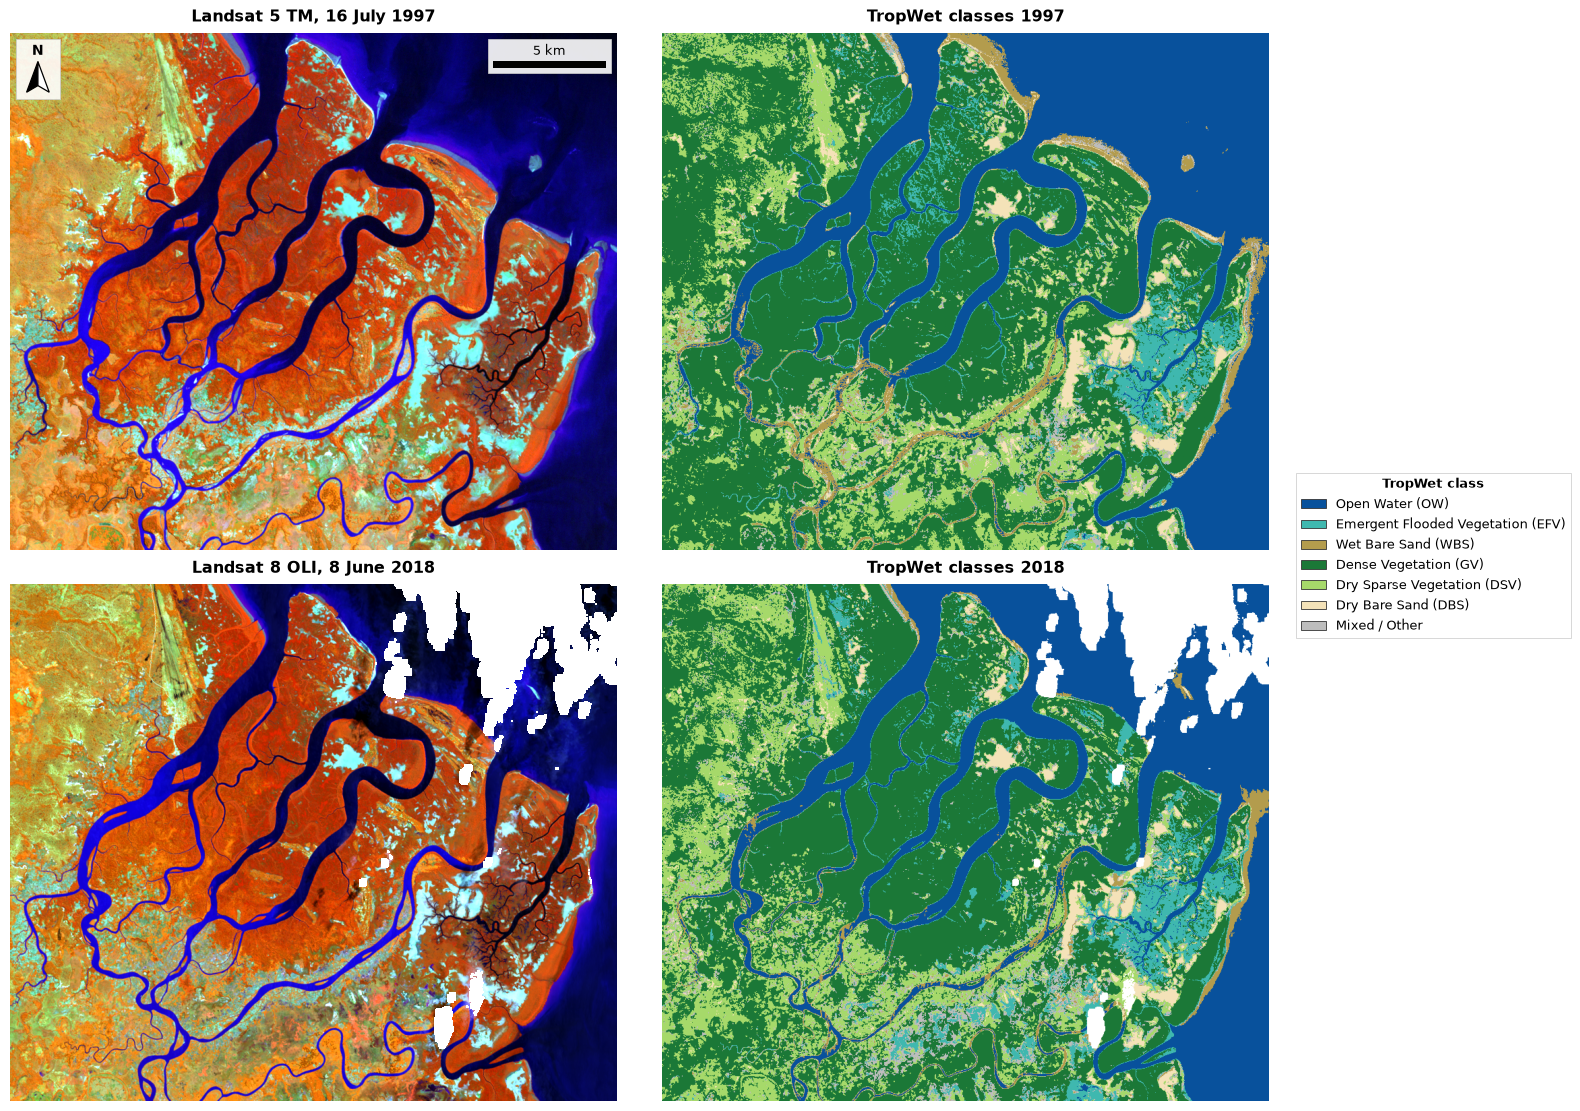

In [5]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", sref_imgs["1997"], bands=[4, 5, 3], title="Landsat 5 TM, 16 July 1997"),
        MapPanel("thematic", cls_imgs["1997"], title="TropWet classes 1997"),
        MapPanel("rgb", sref_imgs["2018"], bands=[4, 5, 3], title="Landsat 8 OLI, 8 June 2018"),
        MapPanel("thematic", cls_imgs["2018"], title="TropWet classes 2018"),
    ],
    ncols=2,
    figsize=(13, 11),
    legend_title="TropWet class",
)

## 4. Change Between 1997 and 2018

### 4.1 Class areas and the from–to table

Only pixels observed on both dates are compared (the 2018 image has cloud and a strip of missing sea). `pd.crosstab` counts the pixels for every pair of classes: rows are the 1997 class and columns the 2018 class, so the diagonal is no change.

In [6]:
cls_arrs = {}
for year in years:
    with rasterio.open(cls_imgs[year]) as src:
        cls_arrs[year] = src.read(1)
        pxl_ha = abs(src.res[0] * src.res[1]) / 10000.0
both_vld = (cls_arrs["1997"] > 0) & (cls_arrs["2018"] > 0)
print(f"Pixels observed on both dates: {both_vld.sum()} ({100 * both_vld.mean():.1f} %)")

from_to_ha = pd.crosstab(
    pd.Series(cls_arrs["1997"][both_vld], name="1997").map(cls_abbrv),
    pd.Series(cls_arrs["2018"][both_vld], name="2018").map(cls_abbrv),
) * pxl_ha
order = list(cls_abbrv.values())
from_to_ha = from_to_ha.reindex(index=order, columns=order, fill_value=0)
from_to_ha.round(0)

Pixels observed on both dates: 650158 (94.2 %)


2018,OW,EFV,WBS,GV,DSV,DBS,Other
1997,,,,,,,
OW,11465.0,178.0,280.0,308.0,18.0,16.0,44.0
EFV,170.0,1457.0,45.0,1137.0,115.0,5.0,146.0
WBS,950.0,64.0,551.0,235.0,161.0,43.0,125.0
GV,44.0,1139.0,65.0,22197.0,4013.0,71.0,1097.0
DSV,34.0,590.0,75.0,1974.0,4251.0,264.0,1077.0
DBS,71.0,45.0,110.0,99.0,285.0,809.0,115.0
Other,115.0,278.0,122.0,770.0,605.0,146.0,537.0


In [7]:
area_df = pd.DataFrame({"1997 (ha)": from_to_ha.sum(axis=1), "2018 (ha)": from_to_ha.sum(axis=0)})
area_df["change (ha)"] = area_df["2018 (ha)"] - area_df["1997 (ha)"]
area_df["unchanged (%)"] = 100 * np.diag(from_to_ha) / area_df["1997 (ha)"]
area_df.round(0)

,1997 (ha),2018 (ha),change (ha),unchanged (%)
OW,12309.0,12849.0,540.0,93.0
EFV,3075.0,3751.0,676.0,47.0
WBS,2129.0,1249.0,-880.0,26.0
GV,28628.0,26722.0,-1906.0,78.0
DSV,8265.0,9448.0,1183.0,51.0
DBS,1534.0,1355.0,-179.0,53.0
Other,2573.0,3140.0,567.0,21.0


The last column is the share of each 1997 class that is the same class in 2018. Open water is the most stable class, and the dense mangrove forest mostly stays Dense Vegetation. The mixed classes (Emergent Flooded Vegetation, Wet Bare Sand, Dry Sparse Vegetation) change much more, largely to and from their neighbours in the fraction triangle: a pixel at 70 % vegetation and 30 % water is Emergent Flooded Vegetation, at 76 % it is Dense Vegetation.

### 4.2 Wetland gain and loss

For a wetland monitoring map, merge the three wetland classes (Open Water, Emergent Flooded Vegetation and Wet Bare Sand) and compare the dates: 1 = stable dry, 2 = stable wetland, 3 = wetland loss (wet in 1997, dry in 2018) and 4 = wetland gain.

In [8]:
wet_chng_img = os.path.join(chg_dir, "wetland_change_1997_2018.tif")
band_maths(
    wet_chng_img,
    "(c97 == 0 || c18 == 0) ? 0 : (c97 <= 3 ? (c18 <= 3 ? 2 : 3) : (c18 <= 3 ? 4 : 1))",
    [BandDefn("c97", cls_imgs["1997"], 1), BandDefn("c18", cls_imgs["2018"], 1)],
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=0,
    use_pbar=False,
)
wet_chng_classes = {
    1: ("Stable dry", "#E0E0E0"),
    2: ("Stable wetland", "#2171B5"),
    3: ("Wetland loss", "#D7301F"),
    4: ("Wetland gain", "#41AB5D"),
}
set_thematic_classes(wet_chng_img, wet_chng_classes)

counts = count_pxls_of_val(wet_chng_img, list(wet_chng_classes), img_band=1, use_pbar=False)
pd.Series(counts * pxl_ha, index=[name for name, _ in wet_chng_classes.values()],
          name="area (ha)").round(0)

Stable dry        38312.0
Stable wetland    15159.0
Wetland loss       2354.0
Wetland gain       2689.0
Name: area (ha), dtype: float64

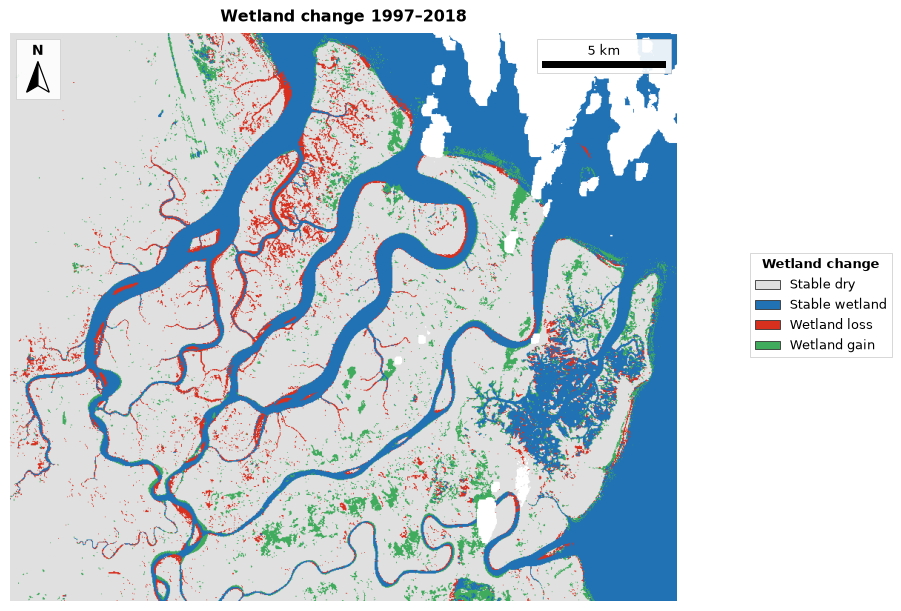

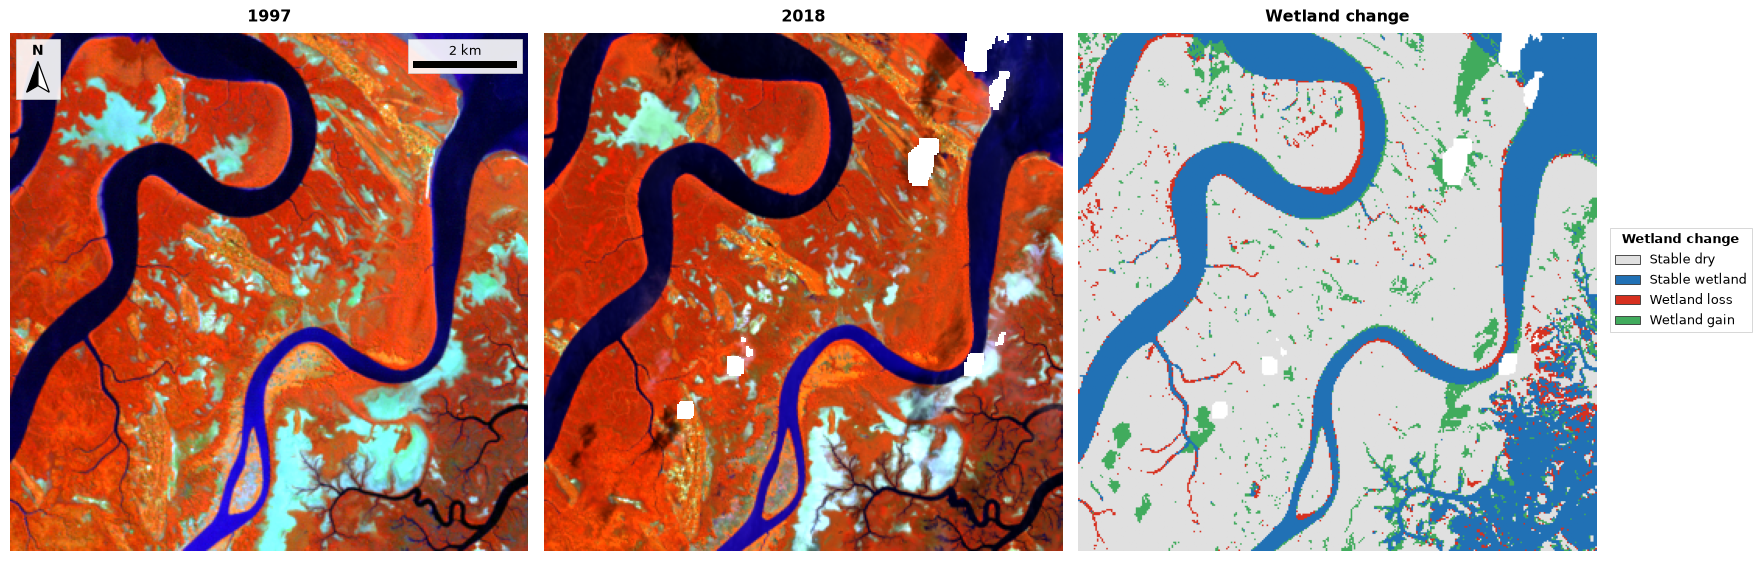

In [9]:
fig, axs = create_map_panels(
    [MapPanel("thematic", wet_chng_img, title="Wetland change 1997–2018")],
    figsize=(8, 6),
    legend_title="Wetland change",
)
# Zoom in on the main river mouths.
fig, axs = create_map_panels(
    [
        MapPanel("rgb", sref_imgs["1997"], bands=[4, 5, 3], title="1997"),
        MapPanel("rgb", sref_imgs["2018"], bands=[4, 5, 3], title="2018"),
        MapPanel("thematic", wet_chng_img, title="Wetland change"),
    ],
    bbox=(536000, 546000, -870000, -860000),
    figsize=(16, 5.5),
    legend_title="Wetland change",
)

### 4.3 Is it real change?

Some of the change is real. Along the meander bends, paired bands of loss and gain show the channels migrating, sand bars have formed and eroded, and the coastline has shifted. The bare salt flats inside the mangroves (cyan in the images) were wetter in June 2018 than in July 1997 and show as wetland gain. But before reporting a from–to table from two images, consider what else differs between them:

- **The tide.** This is a tidal delta. The water level at the two acquisition times is unknown, and a difference of a metre floods or exposes wide mud banks, moving pixels between Open Water, Wet Bare Sand and Emergent Flooded Vegetation. Much of the "change" along the shore and channel banks can be tidal.
- **The season.** The images are from July and June, both in the dry season after the long rains, but the river flow and the state of the farmland still differ between years.
- **The sensors.** Landsat 5 TM and Landsat 8 OLI have slightly different bands and radiometry, and the endmembers were taken from a composite of both. A small shift in the fractions moves pixels across the 75 % and 25 % limits, which notebook 02 showed matter most for the mixed classes.
- **Classes near a limit.** A small change in the fractions flips a pixel near a class limit, but a pixel far from a limit needs a large change. Comparing the fractions (e.g. the change in the water fraction) instead of the classes avoids the limits.

TropWet's own answer is to use **many** observations: classify every cloud-free image in a period and report how often each pixel is water (the water frequency of the guide's Step 8), and compare periods (e.g. this year's wet season with last year's) rather than single dates. Two images can show where change *might* have happened, not how much.

The change in the water fraction shows the same patterns without the class limits:

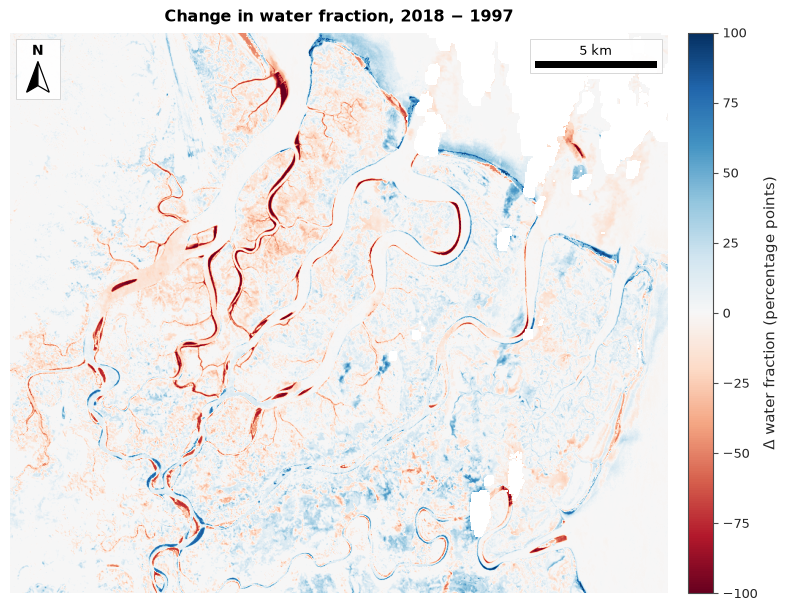

In [10]:
dw_img = os.path.join(chg_dir, "water_fraction_change.tif")
band_maths(
    dw_img,
    "(w97 < 0 || w18 < 0) ? -999 : w18 - w97",
    [BandDefn("w97", pct_imgs["1997"], 1), BandDefn("w18", pct_imgs["2018"], 1)],
    no_data_val=-999,
    use_pbar=False,
)
fig, axs = create_map_panels(
    [MapPanel("cmap", dw_img, bands=1, title="Change in water fraction, 2018 − 1997",
              cmap_name="RdBu", vmin=-100, vmax=100, show_colour_bar=True,
              cbar_label="Δ water fraction (percentage points)")],
    figsize=(8, 6),
)

## 5. Checking the Classes Against Reference Data

### 5.1 Rasterise the reference polygons

Section 6 used polygons of **water**, **mangroves** and **other terrestrial** land, digitised on each image, to train a classifier. Here they are used as reference data. They do not match the TropWet classes one to one: TropWet describes the *surface* (how much water, vegetation and bare ground), while the reference classes are *land cover*. So the first step is to see which TropWet classes each reference class falls into.

The polygons of each class are read with GeoPandas, given a `ref` column with the class value, combined, and burnt onto the classification's grid with `rasterise_vec_lyr` (using `att_column`). Only polygons within the subset are used.

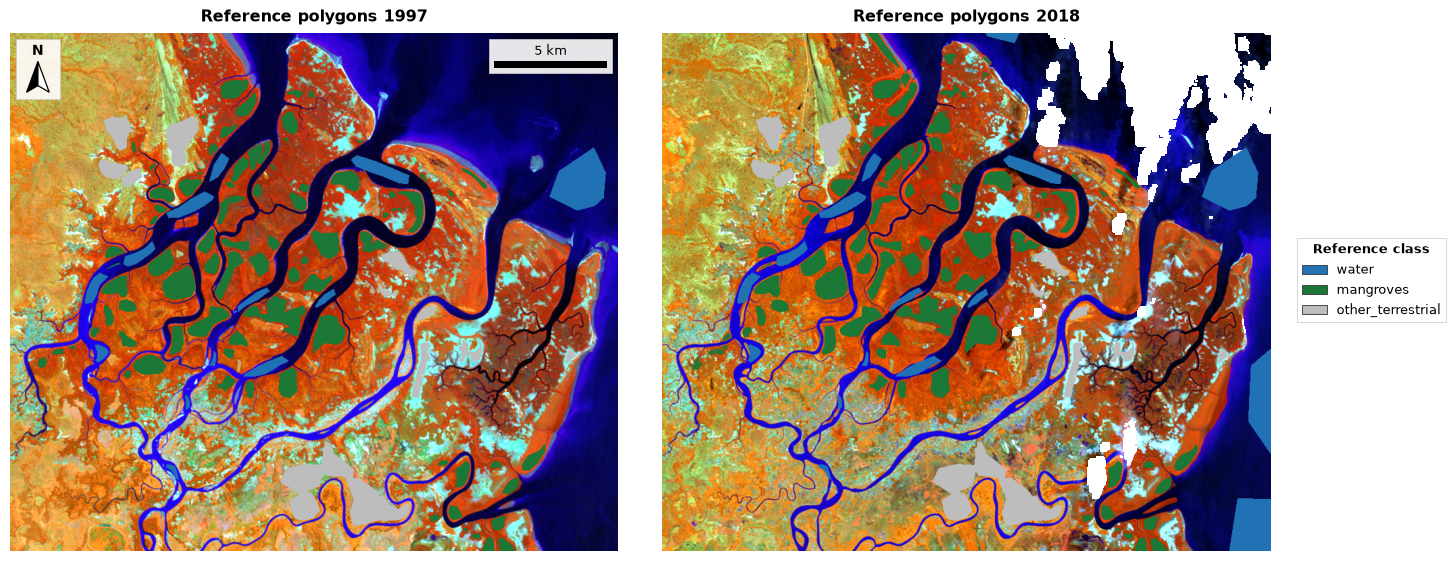

In [11]:
ref_imgs = {}
for year in years:
    ref_gdf = pd.concat(
        [
            geopandas.read_file(os.path.join(ref_dirs[year], f"{name}.geojson")).assign(ref=val)
            for val, name in ref_classes.items()
        ],
        ignore_index=True,
    )
    ref_imgs[year] = os.path.join(chg_dir, f"reference_{year}.tif")
    rasterise_vec_lyr(ref_gdf, None, cls_imgs[year], ref_imgs[year], att_column="ref",
                      use_pbar=False)
    set_thematic_classes(
        ref_imgs[year],
        {1: ("water", "#2171B5"), 2: ("mangroves", "#1B7837"), 3: ("other_terrestrial", "#BDBDBD")},
    )

fig, axs = create_map_panels(
    [MapPanel("thematic", ref_imgs[year], base_img=sref_imgs[year], base_bands=(4, 5, 3),
              title=f"Reference polygons {year}") for year in years],
    figsize=(13, 5.5),
    legend_title="Reference class",
)

### 5.2 Which TropWet classes are the reference classes?

The table gives, for each reference class (rows), the percentage of its pixels in each TropWet class (columns).

In [12]:
ref_tabs = {}
for year in years:
    with rasterio.open(ref_imgs[year]) as src:
        ref_arr = src.read(1)
    msk = (ref_arr > 0) & (cls_arrs[year] > 0)
    ref_tabs[year] = pd.crosstab(
        pd.Series(ref_arr[msk], name="reference").map(ref_classes),
        pd.Series(cls_arrs[year][msk], name="TropWet").map(cls_abbrv),
        normalize="index",
    ).reindex(columns=order, fill_value=0) * 100
    print(f"\n{year} (number of reference pixels: {msk.sum()})")
    print(ref_tabs[year].round(1).to_string())


1997 (number of reference pixels: 62487)
TropWet              OW  EFV  WBS    GV   DSV   DBS  Other
reference                                                 
mangroves           0.1  3.0  0.0  96.9   0.0   0.0    0.0
other_terrestrial   0.0  0.8  0.2  41.9  37.9  14.5    4.6
water              96.4  0.0  3.6   0.0   0.0   0.0    0.0

2018 (number of reference pixels: 70408)
TropWet              OW   EFV  WBS    GV   DSV   DBS  Other
reference                                                  
mangroves           0.0   2.8  0.0  97.1   0.0   0.0    0.1
other_terrestrial   0.1  10.8  0.4  39.7  26.9  10.4   11.7
water              96.9   0.4  1.1   1.3   0.1   0.0    0.2


- **Water** is almost entirely Open Water on both dates (96 % in 1997, 97 % in 2018). The rest is mostly Wet Bare Sand (shallow, turbid water at the edges) and, in 2018, Dense Vegetation or Emergent Flooded Vegetation: narrow creeks next to the mangrove canopy, where a 30 m pixel is mixed.
- **Mangroves** are Dense Vegetation (97 %), with about 3 % Emergent Flooded Vegetation where the forest is open and wet. Mangroves are a wetland, but a closed canopy hides the water underneath, so optical unmixing sees forest: TropWet's wetland classes map the *visible* water.
- **Other terrestrial** land is spread across the classes: about 40 % is green (Dense Vegetation: crops, grassland, woodland), and most of the rest is Dry Sparse Vegetation, Dry Bare Sand or Mixed / Other. In 1997 hardly any of it is in a wetland class, but in 2018 11 % is Emergent Flooded Vegetation: wet or flooded ground within polygons drawn for a land cover classification. These are the pixels to look at in the images before deciding whether TropWet or the reference is wrong.

So TropWet cannot separate mangroves from other dense vegetation (that needs a classifier, as in section 6, or a mangrove habitat mask), but its open water and the dry classes agree well with the reference data.

### 5.3 Accuracy of the open water class

Open water is the one class with a direct reference equivalent, so its accuracy can be measured. A random sample of 500 pixels from each reference class is drawn (pixels within a polygon are not independent, so sampling avoids counting thousands of near-identical pixels; the sample size per class sets the weight of each class). Each point gets a reference label (`Water` or `Not water`) and the TropWet label (`Water` for Open Water, otherwise `Not water`), and `calc_acc_stats_ptonly` calculates the confusion matrix and accuracy statistics.

In [13]:
rng = np.random.default_rng(42)
n_per_cls = 500

acc_stats = {}
for year in years:
    with rasterio.open(ref_imgs[year]) as src:
        ref_arr = src.read(1)
        transform = src.transform
    rows, cols, ref_lbls = [], [], []
    for val in ref_classes:
        r_idx, c_idx = np.nonzero((ref_arr == val) & (cls_arrs[year] > 0))
        sel = rng.choice(r_idx.size, size=min(n_per_cls, r_idx.size), replace=False)
        rows.append(r_idx[sel])
        cols.append(c_idx[sel])
        ref_lbls += [val] * sel.size
    rows, cols = np.concatenate(rows), np.concatenate(cols)
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    pts_gdf = geopandas.GeoDataFrame(
        {
            "ref_class": [ref_classes[val] for val in ref_lbls],
            "ref": ["Water" if val == 1 else "Not water" for val in ref_lbls],
            "tropwet": np.where(cls_arrs[year][rows, cols] == 1, "Water", "Not water"),
        },
        geometry=geopandas.points_from_xy(xs, ys),
        crs="EPSG:32637",
    )
    pts_gdf.to_file(os.path.join(chg_dir, f"acc_points_{year}.gpkg"))
    acc_stats[year] = acc_metrics.calc_acc_stats_ptonly(
        pts_gdf, None, "ref", "tropwet",
        out_json_file=os.path.join(chg_dir, f"acc_open_water_{year}.json"),
    )

# The classes are in alphabetical order: ["Not water", "Water"].
pd.DataFrame(
    {
        year: {
            "overall accuracy (%)": 100 * stats["accuracy"],
            "kappa": stats["cohen_kappa"],
            "water: user's accuracy (%)": stats["user_accuracy"][1],
            "water: producer's accuracy (%)": stats["producer_accuracy"][1],
        }
        for year, stats in acc_stats.items()
    }
).round(2)

,1997,2018
overall accuracy (%),99.07,99.07
kappa,0.98,0.98
water: user's accuracy (%),99.80,100.00
water: producer's accuracy (%),97.40,97.20


In [14]:
for year, stats in acc_stats.items():
    print(year, "confusion matrix (rows = TropWet, columns = reference; Not water, Water):")
    print(np.array(stats["confusion_matrix"]))

1997 confusion matrix (rows = TropWet, columns = reference; Not water, Water):
[[999  13]
 [  1 487]]
2018 confusion matrix (rows = TropWet, columns = reference; Not water, Water):
[[1000   14]
 [   0  486]]


Open water is mapped with an overall accuracy above 99 % on both dates, with a few water reference pixels missed (mixed pixels at the edge of the channels) and almost no false water. This is much higher than the 91 % that Hardy et al. (2020) report for their four merged classes, and it should be: the reference polygons were drawn over clear, homogeneous areas, which are the easiest pixels to classify, and open water is the easiest class. An accuracy from polygons like these is optimistic. A proper assessment uses a stratified random sample over the whole map (e.g. with `rsgispy.classification.classrefpts.create_stratified_random_ref_smpls_lut`), interpreted from imagery close to the image date, as the guide describes in *Checking the results*.

## 6. Summary

- Because TropWet needs no training data, the same endmembers and rules classify any date of the same area; using one endmember set for all dates keeps the fractions comparable.
- The from–to table and the gain / loss map show where the wetland classes changed between 1997 and 2018, but with two images the tide, the season and the sensors are mixed in with real change. Use many observations per period, as TropWet's water frequency does.
- TropWet maps the visible surface: open water agrees closely with the reference polygons, while mangroves are Dense Vegetation like any other closed canopy.

Taken together, notebooks 01–03 show that the TropWet rules are a strong starting point, but that the endmembers, the class limits and the dates all need checking in a new area: the automatic sand endmember described wet mud rather than sand, the mixed classes depend on the class limits, and two dates cannot separate change from tide.

**To apply this to your own data**, the guide's example script runs the whole workflow (with the slope mask from a DEM and the water frequency over all dates) from the command line; add the endmember checks of notebook 01 and the per-pixel model choice of notebook 02 where your area needs them.

Next, notebook `04_finding_endmembers` asks whether the image itself can give better endmembers than the published rules.

**References**
- Hardy, A., Oakes, G., Ettritch, G. (2020). Tropical Wetland (TropWet) Mapping Tool: The Automatic Detection of Open and Vegetated Waterbodies in Google Earth Engine for Tropical Wetlands. *Remote Sensing*, 12(7), 1182. https://doi.org/10.3390/rs12071182

Landsat data courtesy of the U.S. Geological Survey.